In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
file_path = PROJECT_ROOT / "data" / "processed" / "complaints_clean.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (9465, 15)


,complaint_id,make,model,model_year,product_model,filed_date,incident_date,components,crash,fire,number_of_injuries,number_of_deaths,summary,reporting_delay,invalid_incident_date
0,11770133,TOYOTA,CAMRY,2018,CAMRY,2026-10-09,2026-09-29,POWER TRAIN,False,False,0,0,"Total transmission failure at about 107,770 mi...",10.0,False
1,11769969,TOYOTA,CAMRY,2018,CAMRY,2026-10-08,2026-10-06,ENGINE,False,False,0,0,My 2018 Toyota Camry LE went into Limp mode wh...,2.0,False
2,11769124,TOYOTA,CAMRY,2018,CAMRY,2026-10-05,2026-10-03,POWER TRAIN,False,False,0,0,The contact owns a 2018 Toyota Camry. The cont...,2.0,False
3,11768868,TOYOTA,CAMRY,2018,CAMRY,2026-10-04,2026-10-02,FUEL/PROPULSION SYSTEM,False,False,0,0,I am filing a formal complaint regarding a sev...,2.0,False
4,11768335,TOYOTA,CAMRY,2018,CAMRY,2026-10-01,2026-09-29,POWER TRAIN,False,False,0,0,"2018 Toyota Camry approx 126,000 miles. Trans...",2.0,False


In [2]:
print("Missing reporting delays:", df["reporting_delay"].isna().sum())

print("\nReporting delay statistics:")
print(
    df["reporting_delay"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Missing reporting delays: 27

Reporting delay statistics:
count    9438.000000
mean       89.846366
std       229.265791
min         0.000000
25%         2.000000
50%        12.000000
75%        60.000000
90%       239.000000
95%       448.300000
99%      1249.630000
max      2922.000000
Name: reporting_delay, dtype: float64


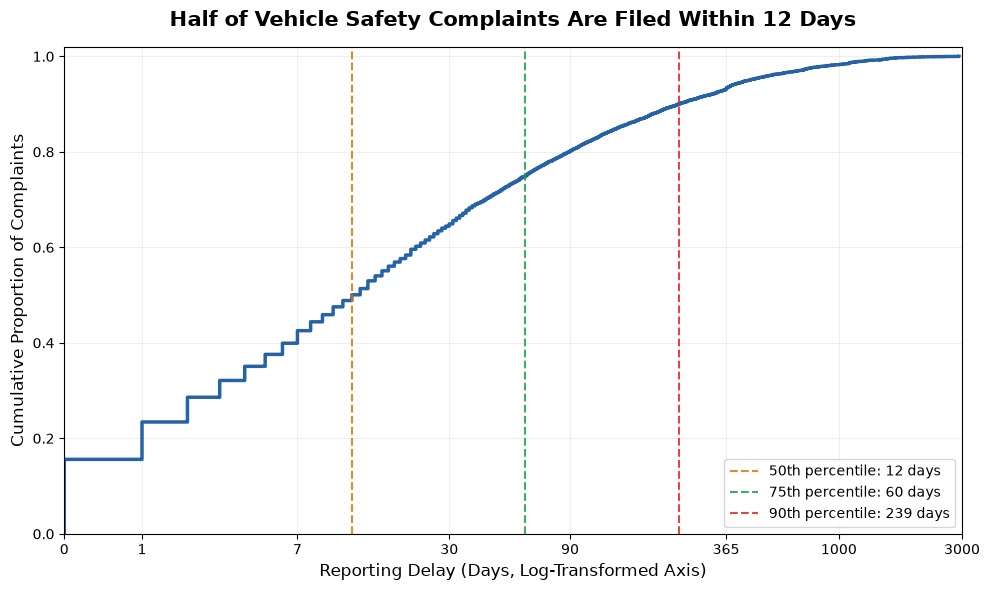

In [6]:
delay = df["reporting_delay"].dropna()

median_delay = delay.median()
p75 = delay.quantile(0.75)
p90 = delay.quantile(0.90)

fig, ax = plt.subplots(figsize=(10, 6))

sns.ecdfplot(
    x=np.log1p(delay),
    ax=ax,
    color="#2563A6",
    linewidth=2.5
)

for value, percentile, color in [
    (median_delay, 50, "#D97706"),
    (p75, 75, "#16A34A"),
    (p90, 90, "#DC2626")
]:
    ax.axvline(
        np.log1p(value),
        color=color,
        linestyle="--",
        alpha=0.85,
        label=f"{percentile}th percentile: {value:.0f} days"
    )

# Show original day values on the transformed axis
ticks = [0, 1, 7, 30, 90, 365, 1000, 3000]
ax.set_xticks(np.log1p(ticks))
ax.set_xticklabels([str(x) for x in ticks])
ax.set_xlim(np.log1p(0), np.log1p(3000))

ax.set_title(
    "Half of Vehicle Safety Complaints Are Filed Within 12 Days",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Reporting Delay (Days, Log-Transformed Axis)", fontsize=12)
ax.set_ylabel("Cumulative Proportion of Complaints", fontsize=12)

ax.set_ylim(0, 1.02)
ax.grid(alpha=0.2)
ax.legend(loc="lower right")

plt.tight_layout()

output_path = PROJECT_ROOT / "figures" / "reporting_delay_ecdf.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

In [7]:
# Create a separate dataframe for this analysis
df_severity = df.copy()

# Convert event indicators to Boolean values
crash = df_severity["crash"].fillna(False).astype(bool)
fire = df_severity["fire"].fillna(False).astype(bool)

# Define severe complaints
df_severity["severe"] = (
    crash
    | fire
    | (df_severity["number_of_injuries"] > 0)
    | (df_severity["number_of_deaths"] > 0)
)

# Keep complaints with valid reporting delays
df_severity = df_severity.dropna(subset=["reporting_delay"])

# Check sample sizes
print("Complaint counts:")
print(df_severity["severe"].value_counts())

# Compare reporting delays
print("\nReporting delay by severity:")
display(
    df_severity.groupby("severe")["reporting_delay"]
    .describe(percentiles=[0.5, 0.75, 0.9])
    .round(1)
)

Complaint counts:
severe
False    8948
True      490
Name: count, dtype: int64

Reporting delay by severity:


,count,mean,std,min,50%,75%,90%,max
severe,,,,,,,,
False,8948.0,89.7,230.2,0.0,12.0,60.0,238.0,2922.0
True,490.0,92.2,211.3,0.0,13.0,67.0,296.2,1673.0


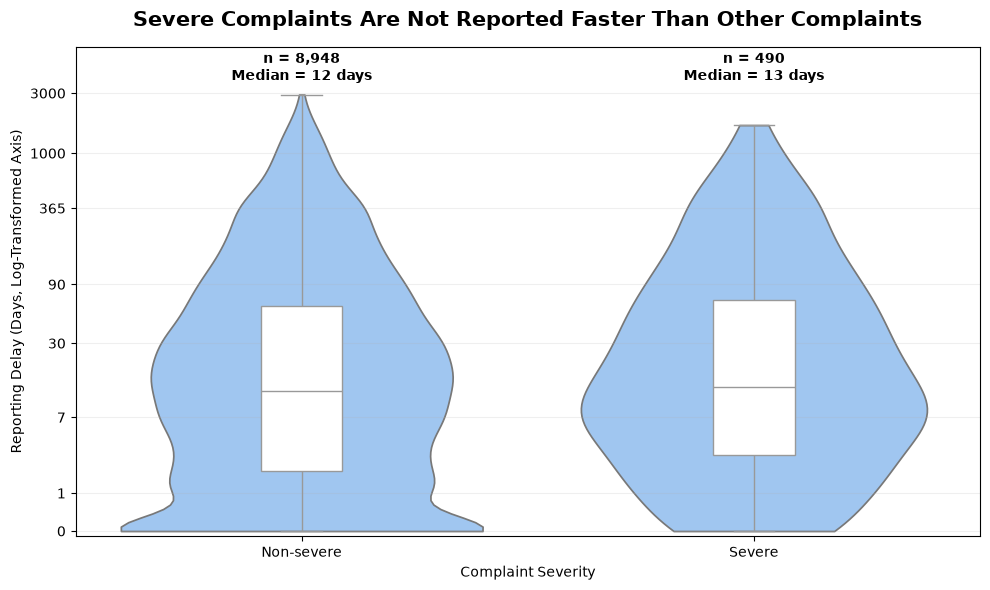

In [10]:
# Prepare plotting data
plot_df = df_severity.copy()

plot_df["Severity"] = plot_df["severe"].map({
    False: "Non-severe",
    True: "Severe"
})

plot_df["Log Delay"] = np.log1p(plot_df["reporting_delay"])

# Create plot
fig, ax = plt.subplots(figsize=(10, 6))

sns.violinplot(
    data=plot_df,
    x="Severity",
    y="Log Delay",
    order=["Non-severe", "Severe"],
    inner=None,
    cut=0,
    color="#93C5FD",
    ax=ax
)

sns.boxplot(
    data=plot_df,
    x="Severity",
    y="Log Delay",
    order=["Non-severe", "Severe"],
    width=0.18,
    showfliers=False,
    color="white",
    ax=ax
)

# Show reporting delay in original days
ticks = [0, 1, 7, 30, 90, 365, 1000, 3000]
ax.set_yticks(np.log1p(ticks))
ax.set_yticklabels([str(x) for x in ticks])

ax.set_title(
    "Severe Complaints Are Not Reported Faster Than Other Complaints",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Complaint Severity")
ax.set_ylabel("Reporting Delay (Days, Log-Transformed Axis)")

ax.grid(axis="y", alpha=0.2)

# Add sample sizes and median annotations
group_info = [
    ("Non-severe", 8948, 12),
    ("Severe", 490, 13)
]

for i, (name, n, median) in enumerate(group_info):
    ax.text(
        i,
        np.log1p(3500),
        f"n = {n:,}\nMedian = {median} days",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_ylim(-0.1, np.log1p(7000))

plt.tight_layout()

output_path = PROJECT_ROOT / "figures" / "severity_reporting_delay.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

In [11]:
# Count complaints for each make-model-year combination
model_year_counts = (
    df.groupby(["make", "model", "model_year"])
    .size()
    .reset_index(name="complaint_count")
)

# Create readable vehicle labels
model_year_counts["vehicle"] = (
    model_year_counts["make"] + " " + model_year_counts["model"]
)

# Convert to a matrix for comparison
model_year_table = model_year_counts.pivot(
    index="vehicle",
    columns="model_year",
    values="complaint_count"
)

display(model_year_table)

model_year,2018,2019,2020
vehicle,,,
AUDI Q5,207,52,25
BMW 3 SERIES,59,41,53
FORD ESCAPE,1812,595,1537
FORD F-150,85,59,50
HONDA CIVIC,596,346,228
HYUNDAI ELANTRA,283,251,253
MERCEDES-BENZ C-CLASS,130,79,46
NISSAN ALTIMA,226,233,179
TOYOTA CAMRY,748,397,275


In [13]:
# Calculate percentages within each vehicle model
model_year_pct = model_year_table.div(
    model_year_table.sum(axis=1),
    axis=0
) * 100

# Sort by the share of 2018 complaints
model_year_pct = model_year_pct.sort_values(2018, ascending=True)

display(model_year_pct.round(1))

model_year,2018,2019,2020
vehicle,,,
NISSAN ALTIMA,35.4,36.5,28.1
HYUNDAI ELANTRA,36.0,31.9,32.1
BMW 3 SERIES,38.6,26.8,34.6
FORD F-150,43.8,30.4,25.8
FORD ESCAPE,45.9,15.1,39.0
VOLKSWAGEN TIGUAN,46.1,31.1,22.7
HONDA CIVIC,50.9,29.6,19.5
MERCEDES-BENZ C-CLASS,51.0,31.0,18.0
TOYOTA CAMRY,52.7,28.0,19.4


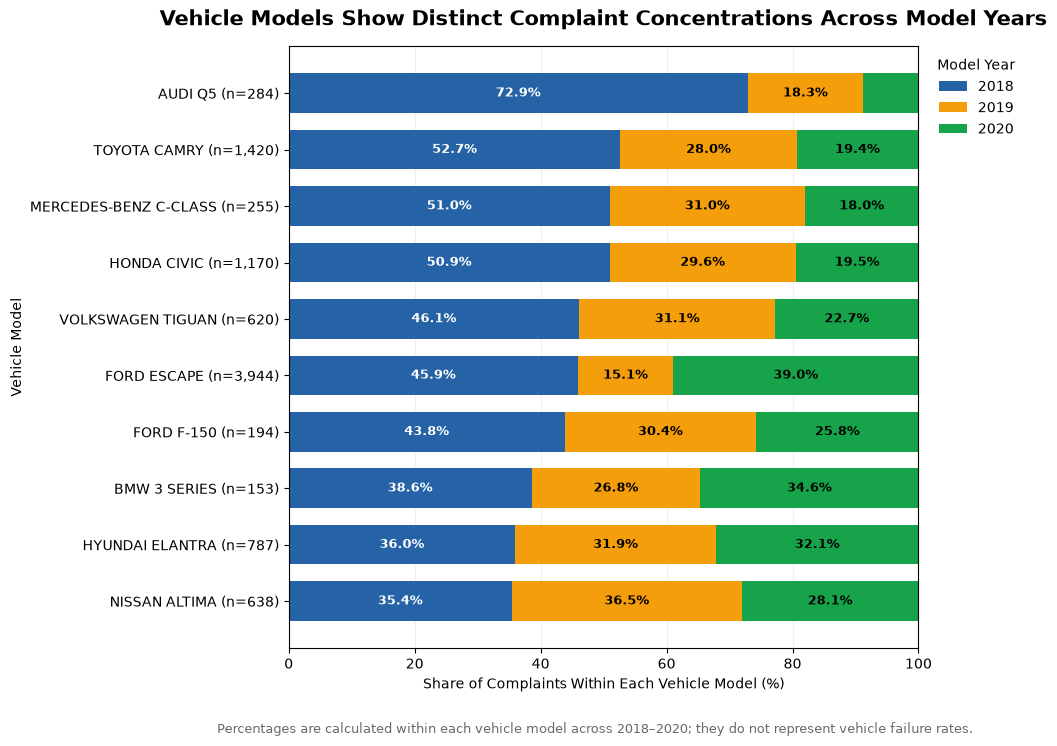

In [15]:
fig, ax = plt.subplots(figsize=(12, 7.5))

colors = ["#2563A6", "#F59E0B", "#16A34A"]
years = [2018, 2019, 2020]

# Add total complaint counts to vehicle labels
totals = model_year_table.sum(axis=1)

labels = [
    f"{vehicle} (n={int(totals.loc[vehicle]):,})"
    for vehicle in model_year_pct.index
]

left = np.zeros(len(model_year_pct))

for i, year in enumerate(years):

    values = model_year_pct[year].values

    bars = ax.barh(
        labels,
        values,
        left=left,
        color=colors[i],
        label=str(year),
        height=0.7
    )

    for bar, value in zip(bars, values):
        if value >= 9:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if i == 0 else "black",
                fontweight="bold"
            )

    left += values

ax.set_xlim(0, 100)

ax.set_xlabel("Share of Complaints Within Each Vehicle Model (%)")
ax.set_ylabel("Vehicle Model")

ax.set_title(
    "Vehicle Models Show Distinct Complaint Concentrations Across Model Years",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Move legend outside the chart
ax.legend(
    title="Model Year",
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    frameon=False
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# Add methodological note
fig.text(
    0.5,
    0.015,
    "Percentages are calculated within each vehicle model across 2018–2020; "
    "they do not represent vehicle failure rates.",
    ha="center",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.05, 0.87, 1])

output_path = (
    PROJECT_ROOT / "figures" /
    "model_year_complaints_percentage.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()